# Análisis administrativo: inventario de productos

**Proyecto:** dashboards de RR.HH. y administración en Power BI
**Dataset:** `zepto_v1.xlsx` (Kaggle), inventario de una tienda de reparto rápido · **Autor y enlace:** *[completar con el autor, el enlace y la licencia de Kaggle]*

**Contenido**
1. Recolección
2. Exploración inicial
3. Hallazgo clave: productos repetidos entre categorías
4. Limpieza y columnas nuevas
5. Estadística descriptiva
6. Visualizaciones
7. Conclusiones
8. Exportación del dataset limpio

> Se ejecuta desde la carpeta `notebooks/`. La limpieza vive en `scripts/limpiar_administrativo.py` y aquí se explica y se verifica.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sys.path.insert(0, "../scripts")
from limpiar_administrativo import limpiar

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 140)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

RAW = Path("../data/raw/zepto_v1.xlsx")
CLEAN = Path("../data/clean/administrativo_limpio.csv")

## 1. Recolección

El archivo se descargó de Kaggle y se guardó **sin modificar** en `data/raw/`. Cada fila es un producto listado en una categoría.

In [2]:
raw = pd.read_excel(RAW)
print("Filas y columnas:", raw.shape)
print("Total de datos (filas x columnas):", raw.size)
raw.head()

Filas y columnas: (3732, 9)
Total de datos (filas x columnas): 33588


,Category,name,mrp,discountPercent,availableQuantity,discountedSellingPrice,weightInGms,outOfStock,quantity
0,Fruits & Vegetables,Onion,2500,16,3,2100,1000,False,1
1,Fruits & Vegetables,Tomato Hybrid,4200,16,3,3500,1000,False,1
2,Fruits & Vegetables,Tender Coconut,5100,15,3,4300,58,False,1
3,Fruits & Vegetables,Coriander Leaves,2000,15,3,1700,100,False,100
4,Fruits & Vegetables,Ladies Finger,1400,14,3,1200,250,False,250


**Requisito de volumen:** 3,732 filas × 9 columnas = **33,588 datos**, por encima del mínimo de 15,000.

## 2. Exploración inicial

In [3]:
print("Tipos de dato:")
print(raw.dtypes.to_string(), "\n")
print("Nulos:", int(raw.isnull().sum().sum()))
print("Filas idénticas en todo (incluida la categoría):", int(raw.duplicated().sum()))
print("Precio de lista en 0:", int((raw["mrp"] == 0).sum()),
      "| peso en 0:", int((raw["weightInGms"] == 0).sum()),
      "| quantity en 0:", int((raw["quantity"] == 0).sum()))
print("Nombres con espacios sobrantes:", int((raw["name"] != raw["name"].str.strip()).sum()), "\n")
print(raw["Category"].value_counts().to_string())
raw.describe().round(2)

Tipos de dato:
Category                    str
name                        str
mrp                       int64
discountPercent           int64
availableQuantity         int64
discountedSellingPrice    int64
weightInGms               int64
outOfStock                 bool
quantity                  int64 

Nulos: 0
Filas idénticas en todo (incluida la categoría): 2
Precio de lista en 0: 1 | peso en 0: 4 | quantity en 0: 6
Nombres con espacios sobrantes: 296 

Category
Cooking Essentials       514
Munchies                 514
Packaged Food            388
Ice Cream & Desserts     388
Chocolates & Candies     388
Personal Care            344
Paan Corner              344
Home & Cleaning          194
Biscuits                 147
Dairy, Bread & Batter    129
Beverages                129
Health & Hygiene          97
Fruits & Vegetables       93
Meats, Fish & Eggs        63


,mrp,discountPercent,availableQuantity,discountedSellingPrice,weightInGms,quantity
count,3732.00,3732.00,3732.00,3732.00,3732.00,3732.00
mean,15680.12,7.62,4.01,14192.83,387.84,213.27
std,16088.81,9.21,2.20,13850.73,678.10,194.73
min,0.00,0.00,0.00,0.00,0.00,0.00
25%,6000.00,0.00,2.00,5500.00,100.00,50.00
50%,11000.00,6.00,5.00,10400.00,225.00,186.00
75%,20000.00,10.00,6.00,18400.00,450.00,340.00
max,260000.00,51.00,6.00,139900.00,10000.00,1500.00


In [4]:
# ¿outOfStock coincide con availableQuantity = 0?
print(pd.crosstab(raw["outOfStock"], raw["availableQuantity"] == 0, rownames=["outOfStock"], colnames=["disponible = 0"]))

# ¿El precio con descuento coincide con mrp x (1 - descuento)?
esperado = raw["mrp"] * (1 - raw["discountPercent"] / 100)
dif = (raw["discountedSellingPrice"] - esperado).abs() / raw["mrp"].where(raw["mrp"] > 0)
print("\nFilas con diferencia mayor a 1 %:", int((dif > 0.01).sum()), "| mayor a 2 %:", int((dif > 0.02).sum()))

print("\nCantidad disponible: máximo", raw["availableQuantity"].max(),
      "| valor más frecuente", raw["availableQuantity"].mode()[0])
print("quantity es igual a weightInGms en", f"{(raw['quantity'] == raw['weightInGms']).mean():.1%}", "de las filas")

disponible = 0  False  True 
outOfStock                  
False            3279      0
True                0    453

Filas con diferencia mayor a 1 %: 0 | mayor a 2 %: 0

Cantidad disponible: máximo 6 | valor más frecuente 6
quantity es igual a weightInGms en 82.6% de las filas


**Qué se observa**
- No hay nulos.
- `outOfStock` coincide exactamente con `availableQuantity = 0`, así que ambas columnas dicen lo mismo.
- Los precios con descuento cuadran con el precio de lista y el porcentaje de descuento.
- `availableQuantity` llega como máximo a 6, que además es su valor más frecuente: probablemente está topado, así que el "valor de inventario" es un indicador relativo y no el valor real del stock.
- `mrp` y `discountedSellingPrice` parecen estar en **paise** (centésimas de rupia): una cebolla de 1 kg con precio 2500 sería ₹25. Se debe confirmar en la descripción de Kaggle.
- `quantity` coincide con `weightInGms` en la mayoría de las filas, por lo que parece el tamaño del paquete y no unidades en stock.

## 3. Hallazgo clave: productos repetidos entre categorías

Al comparar las categorías se ve que varias contienen **exactamente los mismos productos con los mismos valores**.

In [5]:
tmp = raw.copy()
tmp["name"] = tmp["name"].str.strip()
claves = ["name", "mrp", "discountPercent", "availableQuantity", "discountedSellingPrice",
          "weightInGms", "outOfStock", "quantity"]

print("Filas:", len(tmp))
print("Productos distintos ignorando la categoría:", len(tmp.drop_duplicates(subset=claves)))

listas = {c: set(map(tuple, g[claves].values.tolist())) for c, g in tmp.groupby("Category")}
cats = sorted(listas)
pares = []
for i, a in enumerate(cats):
    for b in cats[i + 1:]:
        comunes = len(listas[a] & listas[b])
        menor = min(len(listas[a]), len(listas[b]))
        if comunes / menor > 0.5:
            pares.append((a, b, len(listas[a]), len(listas[b]), comunes, round(comunes / menor * 100, 1)))

pd.DataFrame(pares, columns=["categoría A", "categoría B", "productos A", "productos B",
                             "en común", "% de la más chica"])

Filas: 3732
Productos distintos ignorando la categoría: 1801


,categoría A,categoría B,productos A,productos B,en común,% de la más chica
0,Beverages,"Dairy, Bread & Batter",129,129,129,100.0
1,Chocolates & Candies,Ice Cream & Desserts,388,388,388,100.0
2,Chocolates & Candies,Packaged Food,388,388,388,100.0
3,Cooking Essentials,Munchies,514,514,514,100.0
4,Ice Cream & Desserts,Packaged Food,388,388,388,100.0
5,Paan Corner,Personal Care,343,343,343,100.0


**Consecuencia:** hay 3,732 filas pero solo alrededor de 1,800 productos distintos. Si se suma el valor del inventario sobre todas las filas, los productos repetidos se cuentan dos o tres veces. Por eso el script crea:

- `id_producto`: identificador del producto (el dataset no trae ID),
- `n_categorias`: en cuántas categorías aparece,
- `es_listado_principal`: 1 en la primera aparición de cada producto.

Para **totales** (valor del inventario, cantidad de productos, % de agotados) se usa `es_listado_principal = 1`. Para comparar **categorías** (descuento promedio, tasa de agotados) se usan todas las filas, porque cada categoría debe verse completa.

## 4. Limpieza y columnas nuevas

El script `limpiar_administrativo.py` aplica estos pasos y devuelve un registro de cada uno:

1. Quitar espacios sobrantes en categoría y producto.
2. Eliminar filas idénticas en todas las columnas.
3. Eliminar filas con precio de lista o de venta en 0.
4. Dejar **vacíos** (sin inventar el dato) los ceros imposibles de `peso_gramos` y `cantidad_paquete`.
5. Convertir los precios de paise a rupias (÷ 100).
6. Crear `id_producto`, `n_categorias` y `es_listado_principal`.
7. Crear columnas derivadas: `ahorro_unitario`, `valor_inventario`, `ahorro_potencial`, `agotado_num`, `grupo`, `rango_precio`, `rango_descuento` y `nivel_stock`.

In [6]:
df, log = limpiar(RAW)
display(pd.DataFrame(log, columns=["paso", "qué se hizo", "afectadas", "filas restantes"]))
print("Filas y columnas:", df.shape, "| Total de datos:", df.size)

unicos = df[df["es_listado_principal"] == 1]
print("Productos únicos:", len(unicos), "| listados en 2 o más categorías:", int((unicos["n_categorias"] > 1).sum()))
df.head()

,paso,qué se hizo,afectadas,filas restantes
0,0. Carga,Filas y columnas originales,3732,3732
1,1. Texto,Nombres con espacios sobrantes corregidos (categoria y producto),337,3732
2,2. Duplicados,Filas identicas en todas las columnas eliminadas,2,3730
3,3. Precios,Filas con precio de lista o de venta en 0 eliminadas,1,3729
4,4. Ceros invalidos,peso_gramos = 0 convertido a vacio,4,3729
5,4. Ceros invalidos,cantidad_paquete = 0 convertido a vacio,6,3729
6,5. Unidades,precio_lista y precio_venta divididos entre 100 (paise a rupias),3729,3729
7,6. Identificador,Productos unicos detectados (id_producto),1800,3729
8,6. Identificador,Productos listados en 2 o mas categorias,1281,3729
9,7. Derivadas,Columnas nuevas agregadas,11,3729


Filas y columnas: (3729, 20) | Total de datos: 74580
Productos únicos: 1800 | listados en 2 o más categorías: 1281


,id_producto,categoria,grupo,producto,precio_lista,descuento_pct,precio_venta,ahorro_unitario,cantidad_disponible,agotado,agotado_num,nivel_stock,valor_inventario,ahorro_potencial,peso_gramos,cantidad_paquete,rango_precio,rango_descuento,n_categorias,es_listado_principal
0,P0001,Fruits & Vegetables,Alimentos y bebidas,Onion,25.0,16,21.0,4.0,3,False,0,Medio (3-5),63.0,12.0,1000.0,1.0,0-50,11-20%,1,1
1,P0002,Fruits & Vegetables,Alimentos y bebidas,Tomato Hybrid,42.0,16,35.0,7.0,3,False,0,Medio (3-5),105.0,21.0,1000.0,1.0,0-50,11-20%,1,1
2,P0003,Fruits & Vegetables,Alimentos y bebidas,Tender Coconut,51.0,15,43.0,8.0,3,False,0,Medio (3-5),129.0,24.0,58.0,1.0,51-100,11-20%,1,1
3,P0004,Fruits & Vegetables,Alimentos y bebidas,Coriander Leaves,20.0,15,17.0,3.0,3,False,0,Medio (3-5),51.0,9.0,100.0,100.0,0-50,11-20%,1,1
4,P0005,Fruits & Vegetables,Alimentos y bebidas,Ladies Finger,14.0,14,12.0,2.0,3,False,0,Medio (3-5),36.0,6.0,250.0,250.0,0-50,11-20%,1,1


## 5. Estadística descriptiva

Las estadísticas se calculan sobre **productos únicos**, para que un producto repetido en varias categorías no pese más de una vez.

In [7]:
num = ["precio_lista", "precio_venta", "descuento_pct", "ahorro_unitario",
       "cantidad_disponible", "valor_inventario", "peso_gramos", "cantidad_paquete"]

resumen = pd.DataFrame({
    "n": unicos[num].count(),
    "media": unicos[num].mean(),
    "mediana": unicos[num].median(),
    "moda": unicos[num].mode().iloc[0],
    "desv_std": unicos[num].std(),
    "minimo": unicos[num].min(),
    "maximo": unicos[num].max(),
}).round(2)
resumen

,n,media,mediana,moda,desv_std,minimo,maximo
precio_lista,1800,153.16,105.0,60.0,162.71,10.0,2600.0
precio_venta,1800,138.66,99.0,25.0,139.66,9.0,1399.0
descuento_pct,1800,7.72,6.0,0.0,8.84,0.0,51.0
ahorro_unitario,1800,14.50,6.0,0.0,40.69,0.0,1201.0
cantidad_disponible,1800,4.00,5.0,6.0,2.20,0.0,6.0
valor_inventario,1800,588.03,378.0,0.0,747.99,0.0,8394.0
peso_gramos,1798,389.26,200.0,200.0,701.20,1.0,10000.0
cantidad_paquete,1797,201.55,150.0,200.0,196.66,1.0,1500.0


**Interpretación**
- **Precio de lista:** media ₹153.2, mediana ₹105 y moda ₹60. La media supera mucho a la mediana y la desviación estándar (₹162.7) es mayor que la media: hay pocos productos caros que jalan el promedio (asimetría a la derecha), por eso conviene la escala logarítmica en las gráficas.
- **Descuento:** media 7.7 %, mediana 6 % y moda 0 %. Cerca del 30 % de los productos no tiene descuento.
- **Cantidad disponible:** media 4.0, mediana 5 y moda 6. La distribución está concentrada en el tope de 6 unidades.
- **Peso y cantidad por paquete:** `n` es menor que el total porque se dejaron vacíos los ceros inválidos; los promedios los ignoran.

## 6. Visualizaciones

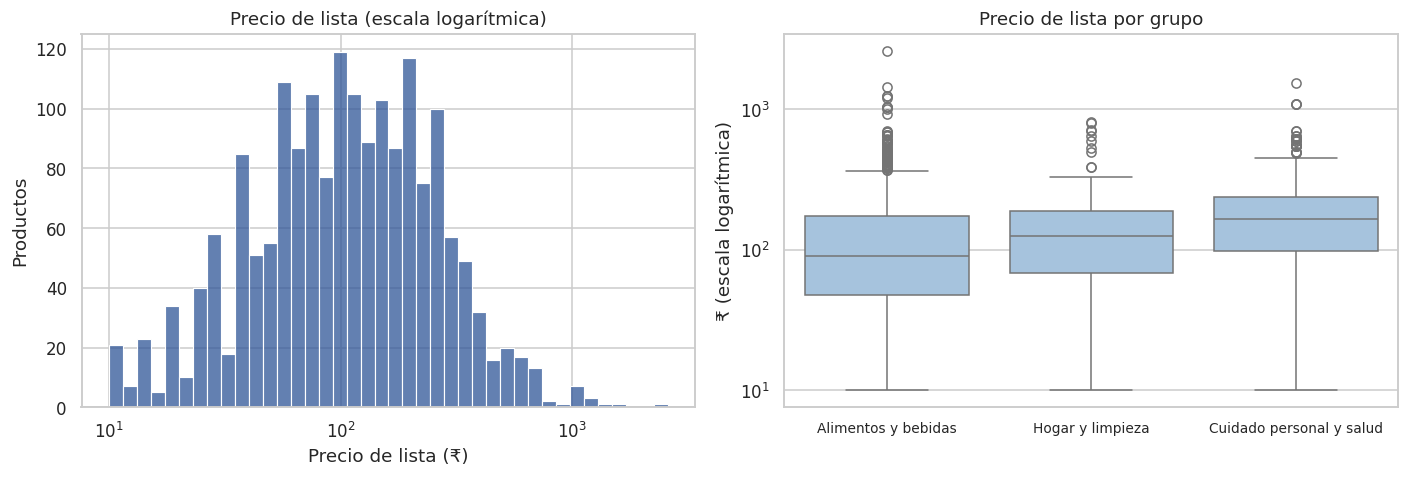

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(unicos["precio_lista"], bins=40, log_scale=True, ax=axes[0], color="#2F5597")
axes[0].set_title("Precio de lista (escala logarítmica)")
axes[0].set_xlabel("Precio de lista (₹)")
axes[0].set_ylabel("Productos")

orden = unicos.groupby("grupo")["precio_lista"].median().sort_values().index
sns.boxplot(data=unicos, x="grupo", y="precio_lista", order=orden, ax=axes[1], color="#9DC3E6")
axes[1].set_yscale("log")
axes[1].set_title("Precio de lista por grupo")
axes[1].set_xlabel("")
axes[1].set_ylabel("₹ (escala logarítmica)")
axes[1].tick_params(axis="x", labelsize=9)
plt.tight_layout()
plt.show()

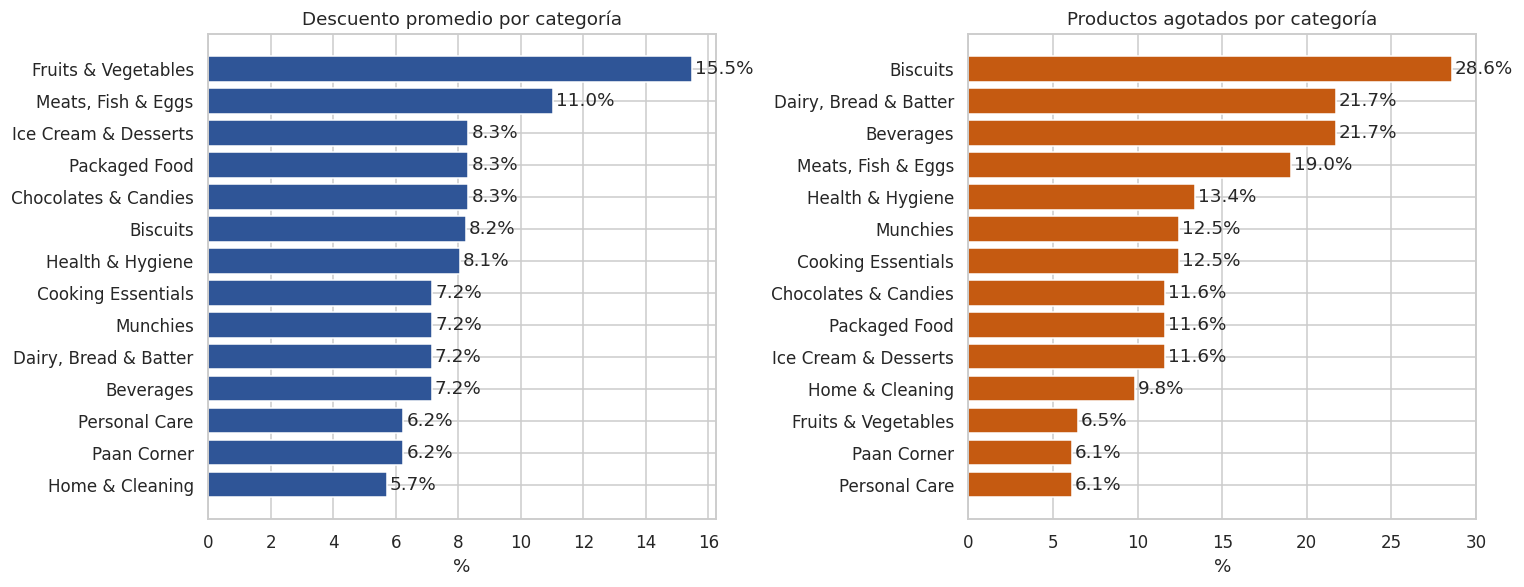

In [9]:
por_cat = df.groupby("categoria").agg(descuento=("descuento_pct", "mean"), agotados=("agotado_num", "mean"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
d = por_cat["descuento"].sort_values()
axes[0].barh(d.index, d.values, color="#2F5597")
axes[0].bar_label(axes[0].containers[0], fmt="%.1f%%", padding=2)
axes[0].set_title("Descuento promedio por categoría")
axes[0].set_xlabel("%")

a = (por_cat["agotados"] * 100).sort_values()
axes[1].barh(a.index, a.values, color="#C55A11")
axes[1].bar_label(axes[1].containers[0], fmt="%.1f%%", padding=2)
axes[1].set_title("Productos agotados por categoría")
axes[1].set_xlabel("%")
plt.tight_layout()
plt.show()

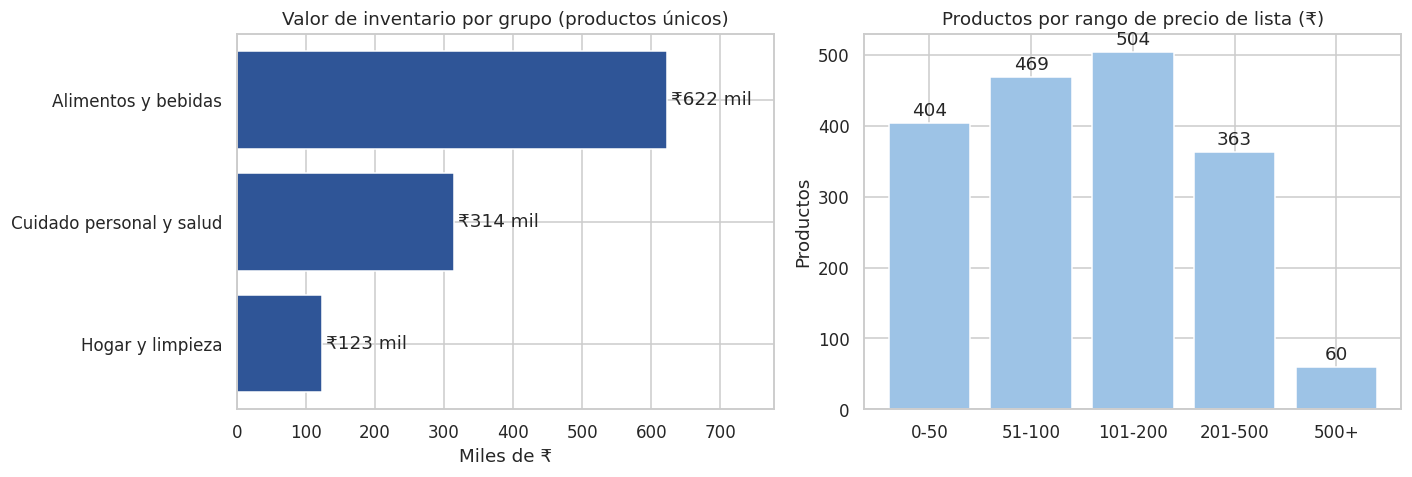

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

v = (unicos.groupby("grupo")["valor_inventario"].sum() / 1000).sort_values()
axes[0].barh(v.index, v.values, color="#2F5597")
axes[0].bar_label(axes[0].containers[0], labels=[f"₹{x:,.0f} mil" for x in v.values], padding=3)
axes[0].set_title("Valor de inventario por grupo (productos únicos)")
axes[0].set_xlabel("Miles de ₹")
axes[0].set_xlim(0, v.max() * 1.25)

rango = unicos["rango_precio"].value_counts().reindex(["0-50", "51-100", "101-200", "201-500", "500+"])
axes[1].bar(rango.index, rango.values, color="#9DC3E6")
axes[1].bar_label(axes[1].containers[0], padding=2)
axes[1].set_title("Productos por rango de precio de lista (₹)")
axes[1].set_ylabel("Productos")
plt.tight_layout()
plt.show()

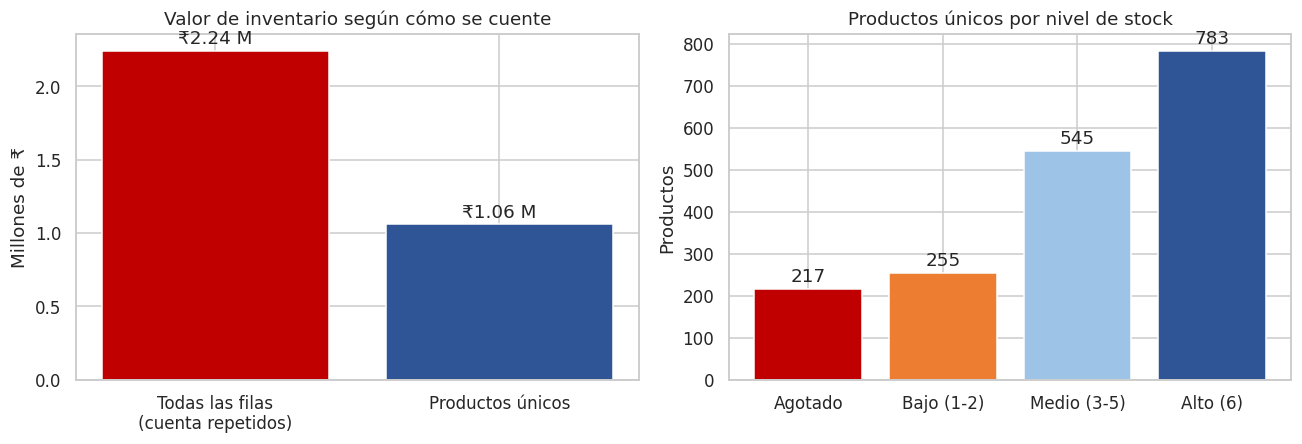

Contar todas las filas multiplica el valor por 2.12


In [11]:
total_filas = df["valor_inventario"].sum() / 1e6
total_unicos = unicos["valor_inventario"].sum() / 1e6

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].bar(["Todas las filas\n(cuenta repetidos)", "Productos únicos"], [total_filas, total_unicos],
            color=["#C00000", "#2F5597"])
axes[0].bar_label(axes[0].containers[0], fmt="₹%.2f M", padding=2)
axes[0].set_title("Valor de inventario según cómo se cuente")
axes[0].set_ylabel("Millones de ₹")

stock = unicos["nivel_stock"].value_counts().reindex(["Agotado", "Bajo (1-2)", "Medio (3-5)", "Alto (6)"])
axes[1].bar(stock.index, stock.values, color=["#C00000", "#ED7D31", "#9DC3E6", "#2F5597"])
axes[1].bar_label(axes[1].containers[0], padding=2)
axes[1].set_title("Productos únicos por nivel de stock")
axes[1].set_ylabel("Productos")
plt.tight_layout()
plt.show()

print(f"Contar todas las filas multiplica el valor por {total_filas / total_unicos:.2f}")

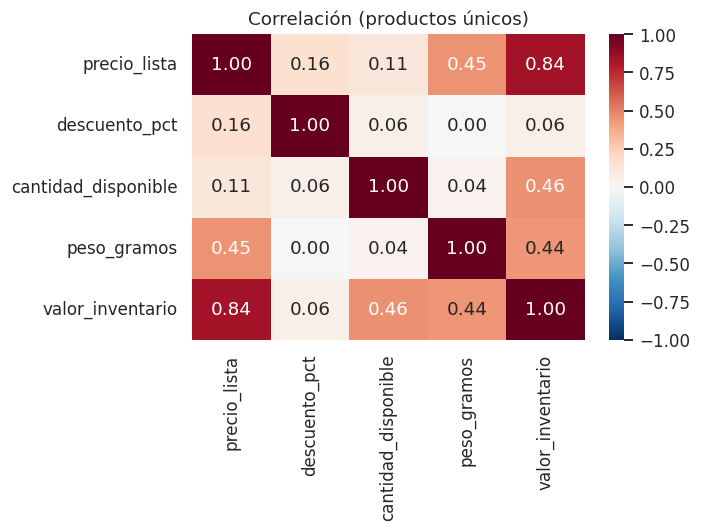

In [12]:
cols = ["precio_lista", "descuento_pct", "cantidad_disponible", "peso_gramos", "valor_inventario"]
plt.figure(figsize=(6.5, 5))
sns.heatmap(unicos[cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlación (productos únicos)")
plt.tight_layout()
plt.show()

**Interpretación**
- El **valor de inventario** de los productos únicos es de ₹1.06 millones; contar todas las filas lo infla a ₹2.24 millones (2.1 veces).
- Por grupo, Alimentos y bebidas concentra cerca del 59 % del valor, Cuidado personal y salud el 30 % y Hogar y limpieza el 12 %.
- **Agotados:** 12.1 % de los productos únicos. Por categoría, Biscuits tiene el mayor porcentaje (28.6 %), seguida de Beverages y Dairy, Bread & Batter (21.7 %) y Meats, Fish & Eggs (19.0 %); Personal Care y Fruits & Vegetables son las más bajas (6.1 % y 6.5 %).
- **Descuento:** Fruits & Vegetables ofrece el mayor descuento promedio (15.5 %) y Home & Cleaning el menor (5.7 %).
- La correlación más alta es entre el precio de lista y el peso (0.45, moderada); el resto es débil.
- Hay categorías con valores idénticos (por ejemplo Personal Care y Paan Corner) porque contienen la misma lista de productos.

## 7. Conclusiones

1. El dataset cumple el volumen (33,588 datos originales; 74,580 tras agregar columnas) y casi no tenía errores, pero esconde un problema estructural: la **misma lista de productos se repite en varias categorías**, por lo que hay solo ~1,800 productos distintos en 3,729 filas.
2. Corregirlo con `id_producto` y `es_listado_principal` evita sobrestimar el inventario en más del doble.
3. Los precios están muy concentrados en valores bajos con una cola de productos caros (media ₹153, mediana ₹105).
4. El 12 % de los productos está agotado y casi el 30 % no tiene descuento; las categorías con más agotados y menos descuento son las candidatas a revisión.
5. Limitaciones: no hay fecha (no se pueden mostrar tendencias), no hay ID de producto original, la cantidad disponible parece topada en 6 y la unidad de los precios (paise) es un supuesto.
6. Para el dashboard: valor de inventario por grupo, productos por rango de precio, descuento promedio y % de agotados por categoría, y tarjetas con productos únicos, valor del inventario y % de agotados.

## 8. Exportación

Se guarda el dataset limpio que consumirá Power BI.

In [13]:
CLEAN.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(CLEAN, index=False)
print("Guardado:", CLEAN, "| filas y columnas:", df.shape, "| datos:", df.size)

Guardado: ../data/clean/administrativo_limpio.csv | filas y columnas: (3729, 20) | datos: 74580
